<div style="font-family:Times New Roman;font-size:14pt;color:black"><b>Лабораторна робота 9</b><br>Згорткові нейронні мережі та перенесення навчання<br>Виконав Шиндир Олексій<br>4 курс, 10 група</div>

<a href="https://colab.research.google.com/github/raysewww-lang/mashynne-navchannia/blob/main/%D0%A8%D0%B8%D0%BD%D0%B4%D0%B8%D1%80_%D0%BF%D1%80_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Відкрити в Colab"/></a>

In [1]:
# Підготовка бібліотек і даних. Дані автоматично завантажуються з GitHub; резервний спосіб — data.zip.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
np.random.seed(25)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'font.size':14,'figure.figsize':(9,5)})
pd.set_option('display.max_columns',40)

def data_path(name):
    for folder in [Path('data'),Path('.'),Path('/content/data'),Path('/content')]:
        p=folder/name
        if p.exists():
            return p
    import zipfile, io
    from urllib.request import urlopen
    try:
        url='https://raw.githubusercontent.com/raysewww-lang/mashynne-navchannia/main/data.zip'
        with urlopen(url, timeout=60) as response:
            content=response.read()
        Path('data').mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if not member.endswith('/'):
                    (Path('data')/Path(member).name).write_bytes(z.read(member))
        if (Path('data')/name).exists():
            return Path('data')/name
    except Exception as error:
        print('Автоматичне завантаження недоступне:',error)
    from google.colab import files
    import zipfile, io
    print('Завантажте data.zip або файл',name)
    uploaded=files.upload()
    Path('data').mkdir(exist_ok=True)
    for fname,content in uploaded.items():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    if not member.endswith('/'):
                        (Path('data')/Path(member).name).write_bytes(z.read(member))
        else:
            (Path('data')/Path(fname).name).write_bytes(content)
    p=Path('data')/name
    if not p.exists():
        raise FileNotFoundError(name)
    return p

In [2]:
# Підготовка TensorFlow і функцій оцінки.
import os
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(25)
try:
    tf.config.threading.set_inter_op_parallelism_threads(2)
    tf.config.threading.set_intra_op_parallelism_threads(2)
except RuntimeError:
    pass
def callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True),keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=2,min_lr=1e-6)]
def curves(history,title):
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,metric in zip(axes,['loss','accuracy']):
        ax.plot(history.history[metric],label='Train')
        ax.plot(history.history['val_'+metric],label='Validation')
        ax.set(xlabel='Епоха',ylabel=metric,title=title);ax.legend()
    plt.tight_layout();plt.show()
def recognition(model,x,y,names):
    p=model.predict(x,verbose=0).argmax(axis=1)
    print(classification_report(y,p,target_names=names,zero_division=0))
    fig,axes=plt.subplots(2,5,figsize=(15,6))
    for i,ax in enumerate(axes.flat):
        ax.imshow(x[i].squeeze(),cmap='gray');ax.axis('off')
        ax.set_title('Іст.: '+names[int(y[i])]+'\nПр.: '+names[int(p[i])],fontsize=11)
    plt.tight_layout();plt.show()
    return p

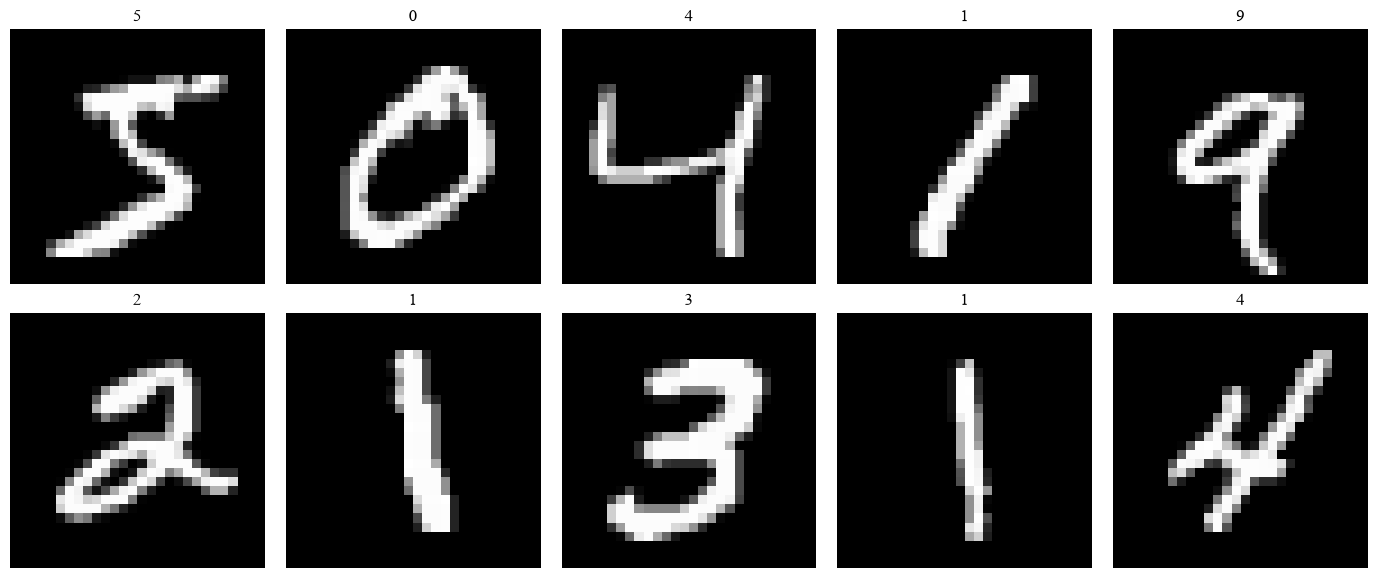

Для навчального експерименту стратифіковано обрано 12000 train, 3000 validation і 3000 незалежних test. Обидві моделі використовують однакові вибірки.


In [3]:
# Завдання 1. Пункти 1–2: завантажити mnist, показати 10 зображень, підготувати однакові вибірки для двох моделей.
(raw_x,raw_y),(raw_test,raw_test_y)=keras.datasets.mnist.load_data()
names=[str(i) for i in range(10)]
fig,axes=plt.subplots(2,5,figsize=(14,6))
for i,ax in enumerate(axes.flat):
    ax.imshow(raw_x[i],cmap='gray');ax.set_title(names[raw_y[i]],fontsize=12);ax.axis('off')
plt.tight_layout();plt.show()
indices,_=train_test_split(np.arange(len(raw_y)),train_size=15000,stratify=raw_y,random_state=25)
test_indices,_=train_test_split(np.arange(len(raw_test_y)),train_size=3000,stratify=raw_test_y,random_state=25)
x=raw_x[indices].astype('float32')[...,None]/255;y=raw_y[indices]
x_test=raw_test[test_indices].astype('float32')[...,None]/255;y_test=raw_test_y[test_indices]
x_train,x_val,y_train,y_val=train_test_split(x,y,test_size=0.2,stratify=y,random_state=25)
print('Для навчального експерименту стратифіковано обрано 12000 train, 3000 validation і 3000 незалежних test. Обидві моделі використовують однакові вибірки.')

In [4]:
# Завдання 1. Пункти 3–5: архітектура CNN, оптимізатор Adam, batch 128, до 8 епох, callbacks і summary.
cnn=keras.Sequential([layers.Input((28,28,1)),layers.Conv2D(16,3,activation='relu'),layers.MaxPooling2D(),layers.Conv2D(32,3,activation='relu'),layers.MaxPooling2D(),layers.Flatten(),layers.Dense(64,activation='relu'),layers.Dropout(0.3),layers.Dense(10,activation='softmax')])
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
cnn.summary()
history=cnn.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=8,batch_size=128,callbacks=callbacks(),verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8


... (11 outputs left out)

Epoch 7/8


94/94 - 1s - 9ms/step - accuracy: 0.9593 - loss: 0.1279 - val_accuracy: 0.9673 - val_loss: 0.1147 - learning_rate: 0.0010


Epoch 8/8


94/94 - 1s - 10ms/step - accuracy: 0.9672 - loss: 0.1077 - val_accuracy: 0.9680 - val_loss: 0.1154 - learning_rate: 0.0010


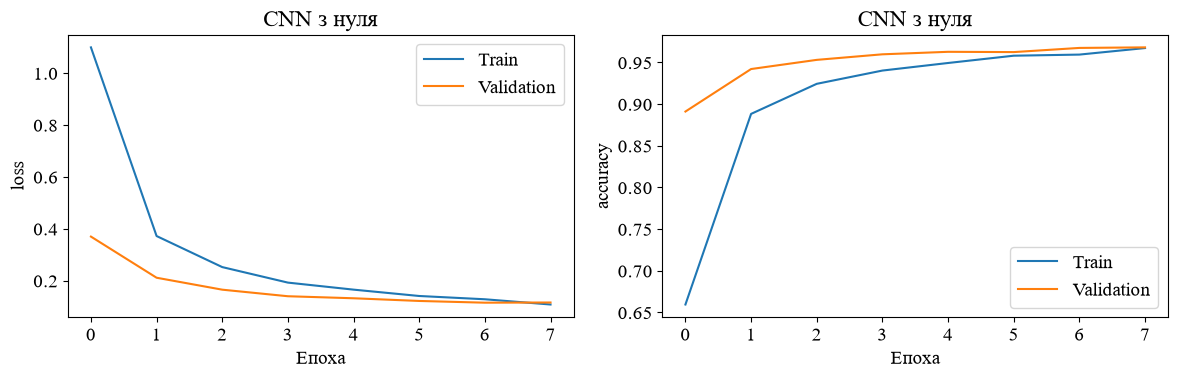

CNN test loss: 0.07888606190681458 accuracy: 0.9766666889190674


              precision    recall  f1-score   support

           0       0.97      1.00      0.98       294
           1       0.99      0.99      0.99       340
           2       0.97      0.96      0.96       310
           3       0.97      0.97      0.97       303
           4       0.99      0.99      0.99       295
           5       0.98      0.98      0.98       268
           6       0.99      0.98      0.98       287
           7       0.96      0.97      0.97       308
           8       0.95      0.97      0.96       292
           9       0.99      0.96      0.97       303

    accuracy                           0.98      3000
   macro avg       0.98      0.98      0.98      3000
weighted avg       0.98      0.98      0.98      3000



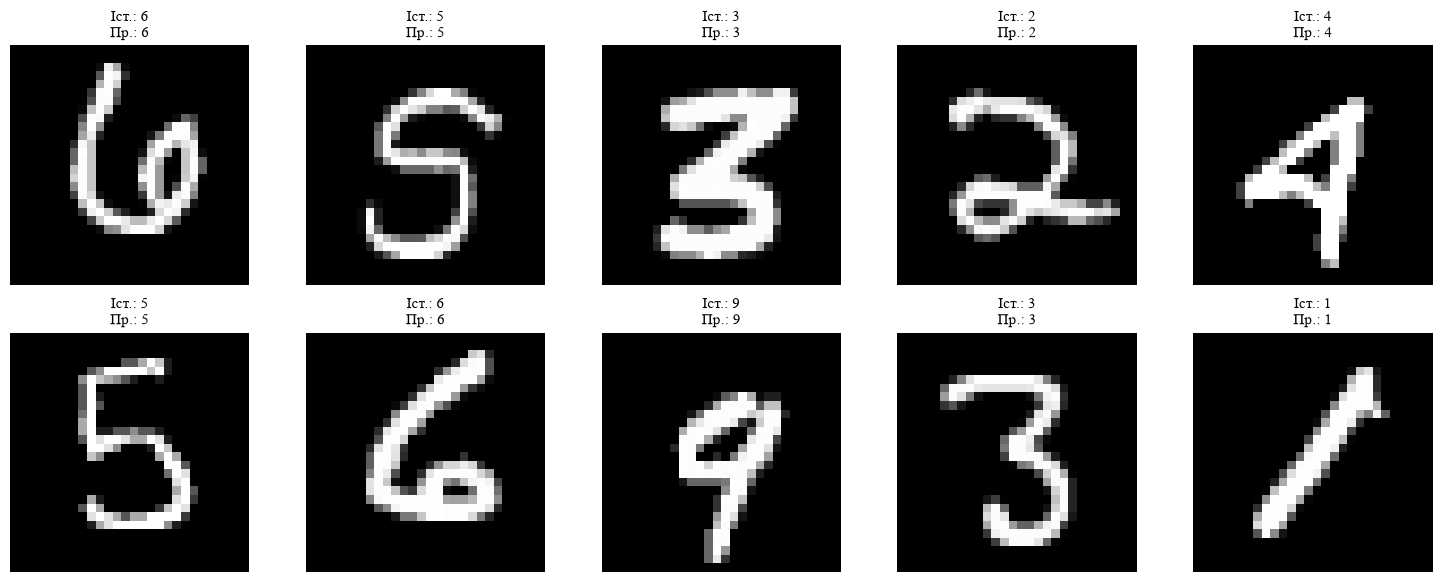

array([6, 5, 3, ..., 9, 5, 1], shape=(3000,))

In [5]:
# Завдання 1. Пункти 6–8: графіки loss/accuracy, classification report, візуалізація розпізнавання.
curves(history,'CNN з нуля')
cnn_loss,cnn_acc=cnn.evaluate(x_test,y_test,verbose=0)
print('CNN test loss:',cnn_loss,'accuracy:',cnn_acc)
recognition(cnn,x_test,y_test,names)

In [6]:
# Завдання 2. Попередньо навчена MobileNetV2 ImageNet. Заморозити базу, додати класифікатор і підготувати зображення.
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
base=MobileNetV2(weights='imagenet',include_top=False,input_shape=(96,96,3),alpha=0.35)
base.trainable=False
inputs=keras.Input((28,28,1))
z=layers.Resizing(96,96)(inputs)
z=layers.Concatenate()([z,z,z])
z=layers.Rescaling(2.0,offset=-1.0)(z)
z=base(z,training=False)
z=layers.GlobalAveragePooling2D()(z)
z=layers.Dropout(0.2)(z)
outputs=layers.Dense(10,activation='softmax')(z)
transfer=keras.Model(inputs,outputs)
transfer.compile(optimizer=keras.optimizers.Adam(1e-3),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
transfer.summary()
warmup=transfer.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=3,batch_size=64,callbacks=callbacks(),verbose=2)

      0/2019640 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  49152/2019640 ━━━━━━━━━━━━━━━━━━━━ 4s 2us/step

  81920/2019640 ━━━━━━━━━━━━━━━━━━━━ 5s 3us/step

 147456/2019640 ━━━━━━━━━━━━━━━━━━━━ 3s 2us/step

 212992/2019640 ━━━━━━━━━━━━━━━━━━━━ 2s 2us/step

 294912/2019640 ━━━━━━━━━━━━━━━━━━━━ 2s 1us/step

... (13 outputs left out)

Epoch 2/3


188/188 - 11s - 56ms/step - accuracy: 0.9140 - loss: 0.2841 - val_accuracy: 0.9403 - val_loss: 0.2153 - learning_rate: 0.0010


Epoch 3/3


188/188 - 11s - 59ms/step - accuracy: 0.9298 - loss: 0.2257 - val_accuracy: 0.9463 - val_loss: 0.1860 - learning_rate: 0.0010


In [7]:
# Завдання 2. Тонке налаштування: розморозити останні 15 шарів, зберегти BatchNormalization замороженими, малий learning rate і callbacks.
base.trainable=True
for layer in base.layers[:-15]:layer.trainable=False
for layer in base.layers:
    if isinstance(layer,layers.BatchNormalization):layer.trainable=False
transfer.compile(optimizer=keras.optimizers.Adam(1e-5),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
print('Шарів, які донавчаються:',sum(layer.trainable for layer in base.layers))
fine=transfer.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=3,batch_size=64,callbacks=callbacks(),verbose=2)
transfer.summary()

Шарів, які донавчаються: 10
Epoch 1/3


188/188 - 18s - 95ms/step - accuracy: 0.9425 - loss: 0.1727 - val_accuracy: 0.9483 - val_loss: 0.1590 - learning_rate: 1.0000e-05


Epoch 2/3


188/188 - 17s - 89ms/step - accuracy: 0.9493 - loss: 0.1502 - val_accuracy: 0.9500 - val_loss: 0.1510 - learning_rate: 1.0000e-05


Epoch 3/3


188/188 - 12s - 62ms/step - accuracy: 0.9563 - loss: 0.1359 - val_accuracy: 0.9517 - val_loss: 0.1446 - learning_rate: 1.0000e-05


... (2 outputs left out)

 Total params: 891,936 (3.40 MB)

 Trainable params: 234,458 (915.85 KB)

 Non-trainable params: 188,560 (736.56 KB)

 Optimizer params: 468,918 (1.79 MB)

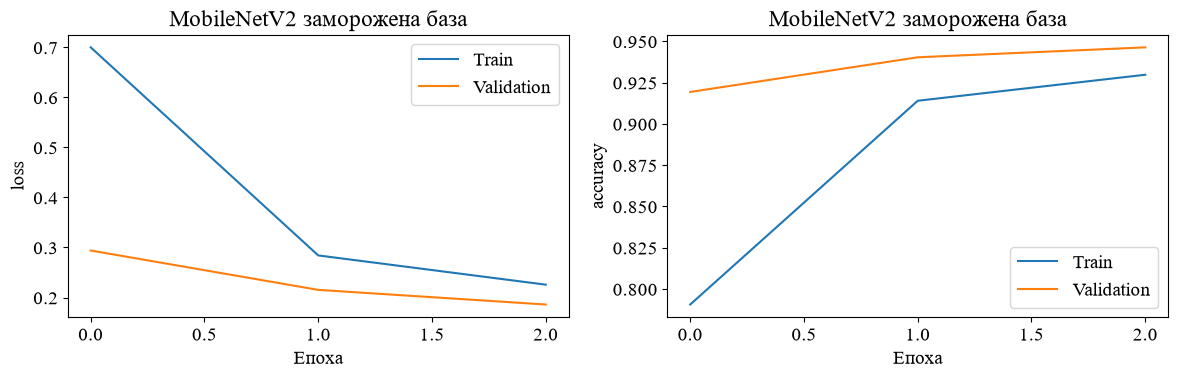

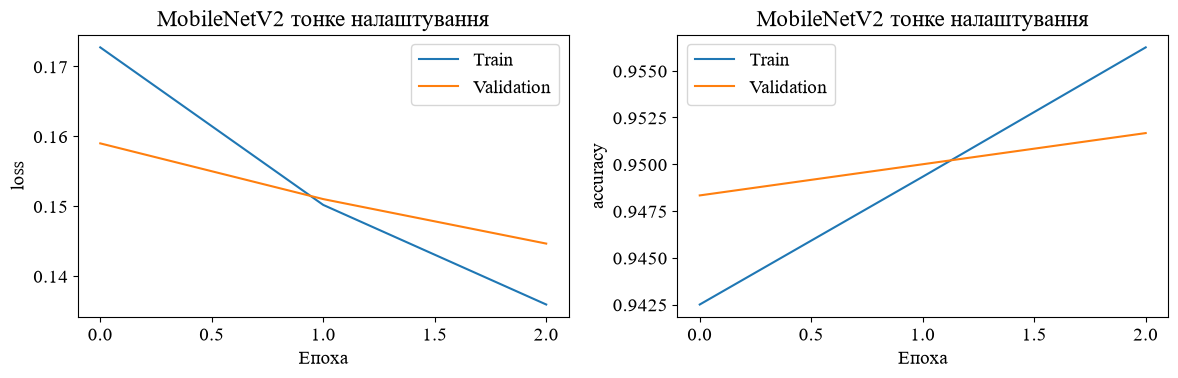

              precision    recall  f1-score   support

           0       0.97      1.00      0.98       294
           1       0.99      0.98      0.99       340
           2       0.95      0.95      0.95       310
           3       0.89      0.93      0.91       303
           4       0.98      0.98      0.98       295
           5       0.92      0.87      0.89       268
           6       0.98      0.96      0.97       287
           7       0.94      0.96      0.95       308
           8       0.96      0.97      0.97       292
           9       0.96      0.96      0.96       303

    accuracy                           0.96      3000
   macro avg       0.96      0.95      0.96      3000
weighted avg       0.96      0.96      0.96      3000



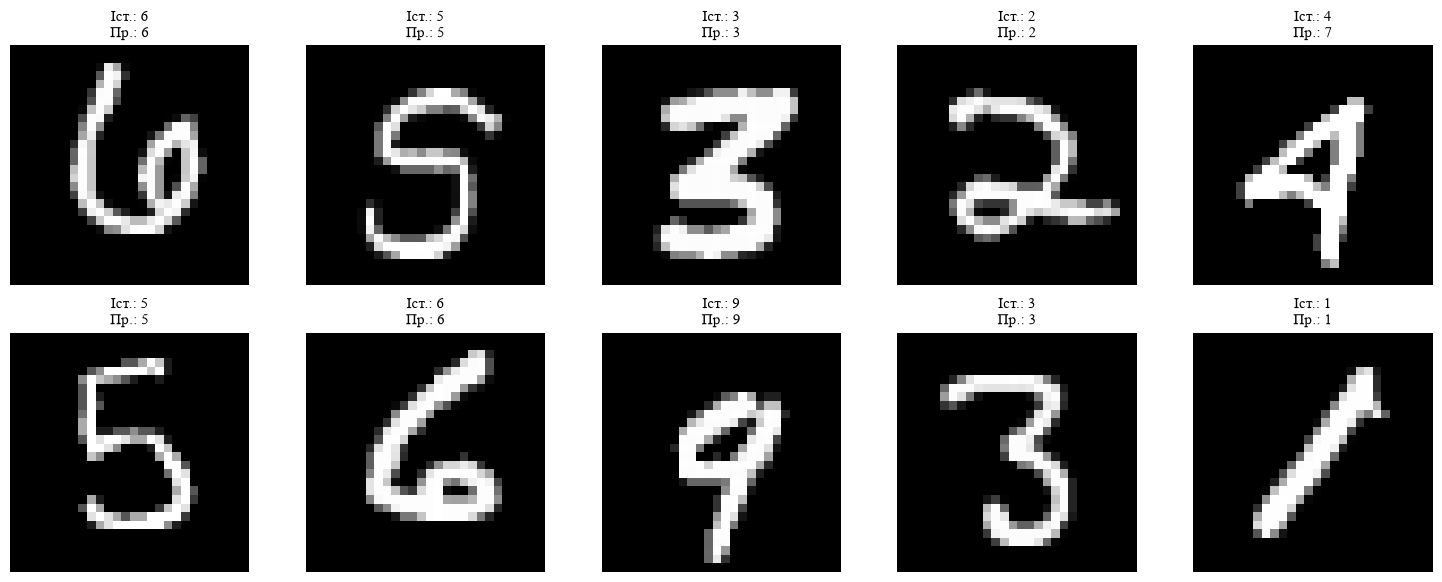

,Модель,Test accuracy,Test loss
0,CNN з нуля,0.976667,0.078886
1,MobileNetV2 fine-tuning,0.956000,0.128097


Різниця accuracy MobileNet - CNN: -0.02066671848297119


In [8]:
# Завдання 2. Повторити оцінку: криві навчання, loss, accuracy, classification report, візуалізація та порівняння.
curves(warmup,'MobileNetV2 заморожена база')
curves(fine,'MobileNetV2 тонке налаштування')
transfer_loss,transfer_acc=transfer.evaluate(x_test,y_test,batch_size=64,verbose=0)
recognition(transfer,x_test,y_test,names)
display(pd.DataFrame({'Модель':['CNN з нуля','MobileNetV2 fine-tuning'],'Test accuracy':[cnn_acc,transfer_acc],'Test loss':[cnn_loss,transfer_loss]}))
print('Різниця accuracy MobileNet - CNN:',transfer_acc-cnn_acc)
Path('models').mkdir(exist_ok=True)
cnn.save('models/Шиндир_пр_9_cnn.keras')
transfer.save('models/Шиндир_пр_9_transfer.keras')

In [9]:
# Висновок. Побудовано CNN з нуля та модель перенесення навчання MobileNetV2 з вагами ImageNet. Додано власний класифікатор, після початкового навчання розморожено частину бази. Обидві моделі оцінено на однаковому незалежному тесті. Таблиця показує, чи допомогло перенесення; воно не гарантує переваги на малих сірих зображеннях. Використано стратифіковану підвибірку, вказану на початку.